# Lab 4: Decision Trees and Pruning

Member 1: Delina Ogbe

Member 2: Sesen Gojela

Member 3: Aditi Shanbhag

Implementations:

In [1]:
#| label: package-setup
needed <- c("ISLR2", "rpart", "knitr")
missing <- needed[!vapply(needed, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing) > 0) {
  install.packages(missing, repos = "https://cloud.r-project.org")
}
stopifnot(all(vapply(needed, requireNamespace, logical(1), quietly = TRUE)))
library(rpart)
knitr::opts_chunk$set(fig.width = 8, fig.height = 5.5, digits = 3)
options(width = 88)
RNGkind("Mersenne-Twister", "Inversion", "Rejection")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
#| label: tree-plot-setup
#| echo: false
# Use exact split labels and the same layout for every tree diagram.
plot_lab_tree <- function(fit, heading, cex = .85) {
  old_par <- par(mar = c(1.5, 1, 3, 1))
  on.exit(par(old_par))
  node_ids <- as.numeric(rownames(fit$frame))
  leaf_count <- sum(fit$frame$var == "<leaf>")
  heading <- paste0(heading, " | ", leaf_count, " leaves")
  if (length(node_ids) == 1L) {
    plot.new()
    title(main = heading)
    text(.5, .5, "Root-only tree: no splits")
    return(invisible(NULL))
  }
  xy <- plot(fit, uniform = TRUE, margin = .08,
             branch.col = "#97A6B5", branch.lwd = 1.5,
             main = heading, cex.main = 1.1)
  text(fit, splits = FALSE, use.n = TRUE, all = FALSE,
       pretty = 0, cex = cex, digits = 4, col = "#19324D")
  internal <- which(fit$frame$var != "<leaf>")
  left_child <- match(2 * node_ids[internal], node_ids)
  split_labels <- labels(fit, digits = 7, minlength = 0)
  text(xy$x[internal], xy$y[internal] + .025 * diff(range(xy$y)),
       split_labels[left_child], cex = cex, col = "#19324D")
  mtext("Left branch: condition true. Right branch: condition false.",
        side = 1, line = .2, cex = .8, col = "#52616F")
}

Section 1: Carseats: data and split

In [3]:
car <- ISLR2::Carseats
car$High <- factor(ifelse(car$Sales > 8, "Yes", "No"),
                   levels = c("No", "Yes"))
car$Sales <- NULL

set.seed(4630)
car_dev_id <- unlist(lapply(
  split(seq_len(nrow(car)), car$High),
  function(i) sample(i, round(.70 * length(i)))))
car_dev <- car[car_dev_id, ]
car_test <- car[-car_dev_id, ]

data.frame(set = c("Development", "Test"),
           n = c(nrow(car_dev), nrow(car_test)))
table(car_dev$High)
prop.table(table(car_dev$High))
colSums(is.na(car_dev))
summary(car_dev[, c("Price", "Advertising", "Age")])
table(Shelf = car_dev$ShelveLoc, High = car_dev$High)

set,n
<chr>,<int>
Development,280
Test,120



 No Yes 
165 115 


       No       Yes 
0.5892857 0.4107143 

CompPrice      Income Advertising  Population       Price   ShelveLoc         Age 
          0           0           0           0           0           0           0 
  Education       Urban          US        High 
          0           0           0           0

     Price        Advertising          Age       
 Min.   : 24.0   Min.   : 0.000   Min.   :25.00  
 1st Qu.:101.0   1st Qu.: 0.000   1st Qu.:39.00  
 Median :118.0   Median : 4.000   Median :54.50  
 Mean   :115.8   Mean   : 6.129   Mean   :53.07  
 3rd Qu.:130.2   3rd Qu.:11.000   3rd Qu.:65.25  
 Max.   :191.0   Max.   :26.000   Max.   :80.00  

        High
Shelf    No Yes
  Bad    55   9
  Good   13  45
  Medium 97  61

Question 1.1:

Response: is High, it lands on "Yes" when Sales are greater than 8 and "No" otherwise.

Classification: The response is a category with two classes

Keeping sales as a predictor: This is misleading because "High" is defined directly from "Sales." For example, if the tree were to split on Sales > 8 it would practically look perfect. However, this would be using the answer to predict the answer. This would also not work in practice because we wouldn't know a store's sales before predicting wheter they will be high or not

Question 1.2:

Development stores: 280
Test stores: 120

165 stores are in class "NO"
Proportion: 165/280 = 0.589

115 stores are in class "YES"
Proportion: 115/280 = 0.411

There are no missing values in the development data. Ever columns count is zero.

Question 1.3:

In [4]:
prop.table(table(Shelf = car_dev$ShelveLoc, High = car_dev$High), 1)

        High
Shelf           No       Yes
  Bad    0.8593750 0.1406250
  Good   0.2241379 0.7758621
  Medium 0.6139241 0.3860759

Based on the pattern we see that better shelf locations align with more high sales stores. Only 14.1% of stores with a Bad shelf location have high sales in comparison to 38.6% for Medium and 77.6% for Good.

It does not show that moving products to a better shelf will cause higher sales. This is just observational data, so we can only say that shelf locations and high sales go together. There are other factors that could into why certain stores with good shelf locations have better sales like better advertising, lower prices, or more customers. Better shelf space could also be given to products that already sell well. The experiment would have needed to have shelf location changed on purpose to show the cause and effect.

Section 2: Grow and interpret a classification tree

Question 2.1:

Parent:
6 No, 4 Yes, 10 Total

$p_{No}=0.6$ and $p_{Yes}=0.4$

$$G_{parent}=1-0.6^2-0.4^2=1-0.36-0.16=0.48 .$$

Left child:
4 No, 0 Yes, 4 Total

$G_{left}=1-1^2-0^2=0$

Right Child:
2 No, 4 Yes, 6 Total

$p_{No}=2/6=1/3$ and $p_{Yes}=4/6=2/3$

$$G_{right}=1-\left(\tfrac13\right)^2-\left(\tfrac23\right)^2=1-\tfrac19-\tfrac49=\tfrac49=0.444 .$$

Size-weighted impurity after the split:

$$\tfrac{4}{10}(0)+\tfrac{6}{10}(0.444)=0.267 $$

Decrease in Impurity:

0.480 - 0.267 = 0.213

Why we weight by the number of observations:

Because the two children don't have the same number of observations. A child with more stores should count more because more stores end up in it. Without weighting, a small pure child would count as much as a large child. A split could look good just because it makes one small, pure group. Weighting gives the average impurity per observation after the split.



Question 2.2:

In [5]:
set.seed(4631)
car_full <- rpart(
  High ~ ., data = car_dev, method = "class",
  parms = list(split = "gini"),
  control = rpart.control(cp = 0, minsplit = 12,
                          minbucket = 4, xval = 10))
print(car_full, digits = 5)

car_train_prob <- predict(car_full, newdata = car_dev,
                          type = "prob")[, "Yes"]
car_train_class <- factor(ifelse(car_train_prob >= .50, "Yes", "No"),
                           levels = c("No", "Yes"))
data.frame(leaves = sum(car_full$frame$var == "<leaf>"),
           training_error = mean(car_train_class != car_dev$High))

n= 280 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

  1) root 280 115 No (0.589286 0.410714)  
    2) ShelveLoc=Bad,Medium 222  70 No (0.684685 0.315315)  
      4) Price>=106.5 149  29 No (0.805369 0.194631)  
        8) Advertising< 14.5 135  20 No (0.851852 0.148148)  
         16) CompPrice< 141.5 108   9 No (0.916667 0.083333)  
           32) Age>=49.5 64   1 No (0.984375 0.015625) *
           33) Age< 49.5 44   8 No (0.818182 0.181818)  
             66) Price>=118.5 33   3 No (0.909091 0.090909)  
              132) Population>=162 20   0 No (1.000000 0.000000) *
              133) Population< 162 13   3 No (0.769231 0.230769)  
                266) CompPrice< 131.5 8   0 No (1.000000 0.000000) *
                267) CompPrice>=131.5 5   2 Yes (0.400000 0.600000) *
             67) Price< 118.5 11   5 No (0.545455 0.454545) *
         17) CompPrice>=141.5 27  11 No (0.592593 0.407407)  
           34) Price>=145 10   0 No (1.000000 0.000000) *
        

leaves,training_error
<int>,<dbl>
19,0.1071429


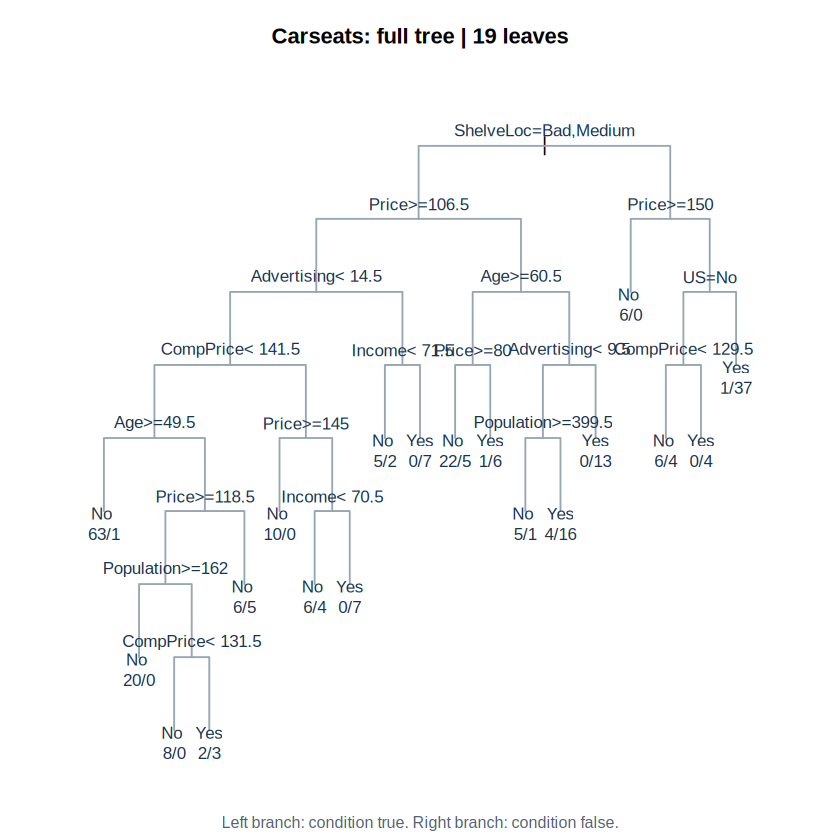

In [6]:
plot_lab_tree(car_full, "Carseats: full tree", cex = .85)

Leaves: 19

Training error: 0.107 (30 of the 280 development stores are misclassified)

Root split:
ShelveLoc - stores with a bad or medium shelf location go to the left branch and store with a good shelf location go to the right branch.

Why training error is optimistic:
The tree used the same 280 development stores when it was being built and with cp = 0 it keeps splitting until it fits the training stores very closely. This includes random quirks that won't show up again in new stores. So this means it looks better on the stores it has already seen than it will on new stores and the error on new stores will usually be higher than 0.107.

Does using Gini to choose splits mean we must use Gini as the final metric?:
No, Gini impurity is only the rule the tree uses to decide where to split. The final performance should be judged with a metric that actualyy fits our goal like misclassification error, recall, or specficity then measured on held-out data like cross validation or the test set.


Question 2.3:

Leaf with 8 No and 12 Yes:

Probability of Yes: 12/20 = 0.60
Because $0.60\ge0.50$ the predicted class is yes

Leaf with 10 No and 10 Yes:

Probability of Yes: 10/20 = 0.50
based on our rule we predict Yes when the probability is at least 0.50 which includes equality so the predicted class is Yes

Why stores with different predictor values receive the same probability:
A tree splits the data into regions and every store that lands in the same leaf gets the same prediction. This is the fraction of Yes stores in the leaf. Stores in the same leaf can still differ in their predictor values, especially with predictors that weren't used in the splits on the way to that leaf or values on the same side of every split. But, the tree treats them the same. The predictions are flat within each region and only change when a store crosses a split.

Question 3:

In [7]:
printcp(car_full)
car_cp <- car_full$cptable
car_root_error <- car_full$frame$dev[1] / nrow(car_dev)
car_cv <- data.frame(
  CP = car_cp[, "CP"],
  leaves = car_cp[, "nsplit"] + 1,
  training_error = car_cp[, "rel error"] * car_root_error,
  CV_error = car_cp[, "xerror"] * car_root_error,
  CV_SE = car_cp[, "xstd"] * car_root_error)
knitr::kable(car_cv, digits = 4)


Classification tree:
rpart(formula = High ~ ., data = car_dev, method = "class", parms = list(split = "gini"), 
    control = rpart.control(cp = 0, minsplit = 12, minbucket = 4, 
        xval = 10))

Variables actually used in tree construction:
[1] Advertising Age         CompPrice   Income      Population  Price       ShelveLoc  
[8] US         

Root node error: 115/280 = 0.41071

n= 280 

          CP nsplit rel error  xerror     xstd
1  0.2782609      0   1.00000 1.00000 0.071584
2  0.0913043      1   0.72174 0.72174 0.066450
3  0.0521739      3   0.53913 0.59130 0.062394
4  0.0434783      4   0.48696 0.56522 0.061433
5  0.0347826      5   0.44348 0.56522 0.061433
6  0.0260870      6   0.40870 0.51304 0.059340
7  0.0217391      7   0.38261 0.53913 0.060415
8  0.0173913      9   0.33913 0.53913 0.060415
9  0.0086957     12   0.28696 0.53043 0.060063
10 0.0021739     14   0.26957 0.54783 0.060761
11 0.0000000     18   0.26087 0.54783 0.060761




|     CP| leaves| training_error| CV_error|  CV_SE|
|------:|------:|--------------:|--------:|------:|
| 0.2783|      1|         0.4107|   0.4107| 0.0294|
| 0.0913|      2|         0.2964|   0.2964| 0.0273|
| 0.0522|      4|         0.2214|   0.2429| 0.0256|
| 0.0435|      5|         0.2000|   0.2321| 0.0252|
| 0.0348|      6|         0.1821|   0.2321| 0.0252|
| 0.0261|      7|         0.1679|   0.2107| 0.0244|
| 0.0217|      8|         0.1571|   0.2214| 0.0248|
| 0.0174|     10|         0.1393|   0.2214| 0.0248|
| 0.0087|     13|         0.1179|   0.2179| 0.0247|
| 0.0022|     15|         0.1107|   0.2250| 0.0250|
| 0.0000|     19|         0.1071|   0.2250| 0.0250|

In [8]:
car_min_row <- which.min(car_cp[, "xerror"])
car_cp_min <- car_cp[car_min_row, "CP"]
car_cutoff <- car_cp[car_min_row, "xerror"] +
              car_cp[car_min_row, "xstd"]
car_eligible <- which(car_cp[, "xerror"] <= car_cutoff)
car_cp_1se <- max(car_cp[car_eligible, "CP"])

car_min <- prune(car_full, cp = car_cp_min)
car_1se <- prune(car_full, cp = car_cp_1se)
car_models <- list(Grown = car_full, Minimum_CV = car_min, One_SE = car_1se)
car_comparison <- data.frame(
  model = names(car_models),
  CP = c(0, car_cp_min, car_cp_1se),
  leaves = vapply(car_models, function(f) sum(f$frame$var == "<leaf>"),
                   numeric(1)),
  training_error = vapply(car_models, function(f) {
    p <- predict(f, newdata = car_dev, type = "prob")[, "Yes"]
    mean(ifelse(p >= .50, "Yes", "No") != car_dev$High)
  }, numeric(1)))
knitr::kable(car_comparison, digits = 4, row.names = FALSE)



|model      |     CP| leaves| training_error|
|:----------|------:|------:|--------------:|
|Grown      | 0.0000|     19|         0.1071|
|Minimum_CV | 0.0261|      7|         0.1679|
|One_SE     | 0.0435|      5|         0.2000|

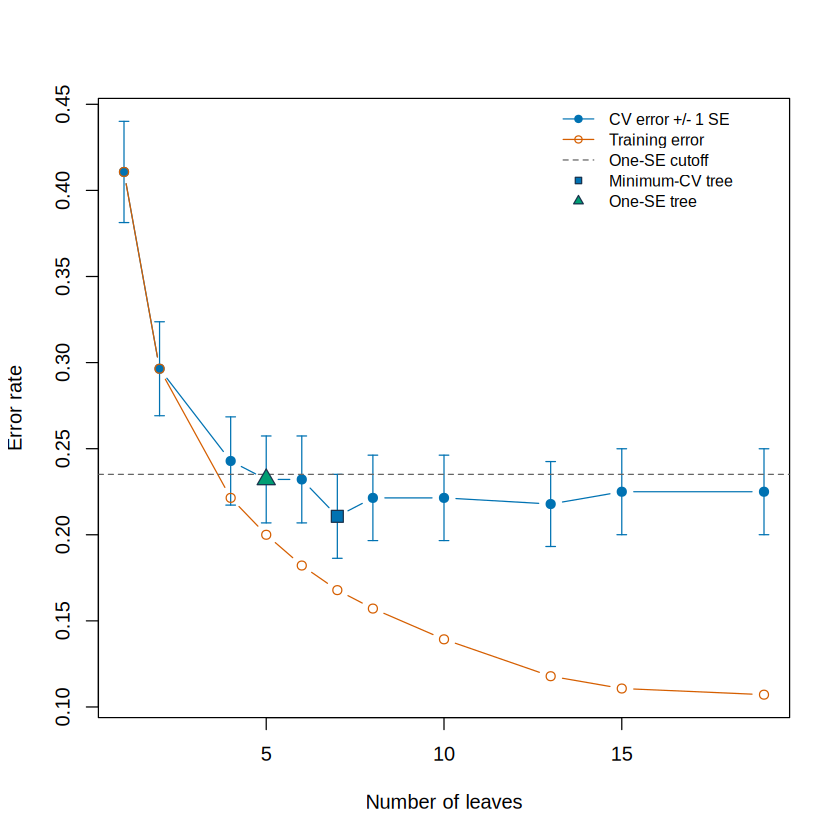

In [9]:
plot(car_cv$leaves, car_cv$CV_error, type = "b", pch = 19,
     col = "#0072B2", xlab = "Number of leaves", ylab = "Error rate",
     ylim = range(c(car_cv$training_error,
                    car_cv$CV_error - car_cv$CV_SE,
                    car_cv$CV_error + car_cv$CV_SE)))
arrows(car_cv$leaves, car_cv$CV_error - car_cv$CV_SE,
       car_cv$leaves, car_cv$CV_error + car_cv$CV_SE,
       angle = 90, code = 3, length = .04, col = "#0072B2")
lines(car_cv$leaves, car_cv$training_error, type = "b", pch = 1,
      col = "#D55E00")
abline(h = car_cutoff * car_root_error, lty = 2, col = "gray40")
car_1se_row <- match(car_cp_1se, car_cp[, "CP"])
points(car_cv$leaves[c(car_min_row, car_1se_row)],
       car_cv$CV_error[c(car_min_row, car_1se_row)],
       pch = c(22, 24), cex = 1.5,
       bg = c("#0072B2", "#009E73"), col = "#19324D")
legend("topright", c("CV error +/- 1 SE", "Training error", "One-SE cutoff",
                     "Minimum-CV tree", "One-SE tree"),
       col = c("#0072B2", "#D55E00", "gray40", "#19324D", "#19324D"),
       lty = c(1, 1, 2, NA, NA), pch = c(19, 1, NA, 22, 24),
       pt.bg = c(NA, NA, NA, "#0072B2", "#009E73"),
       bty = "n", cex = .8)

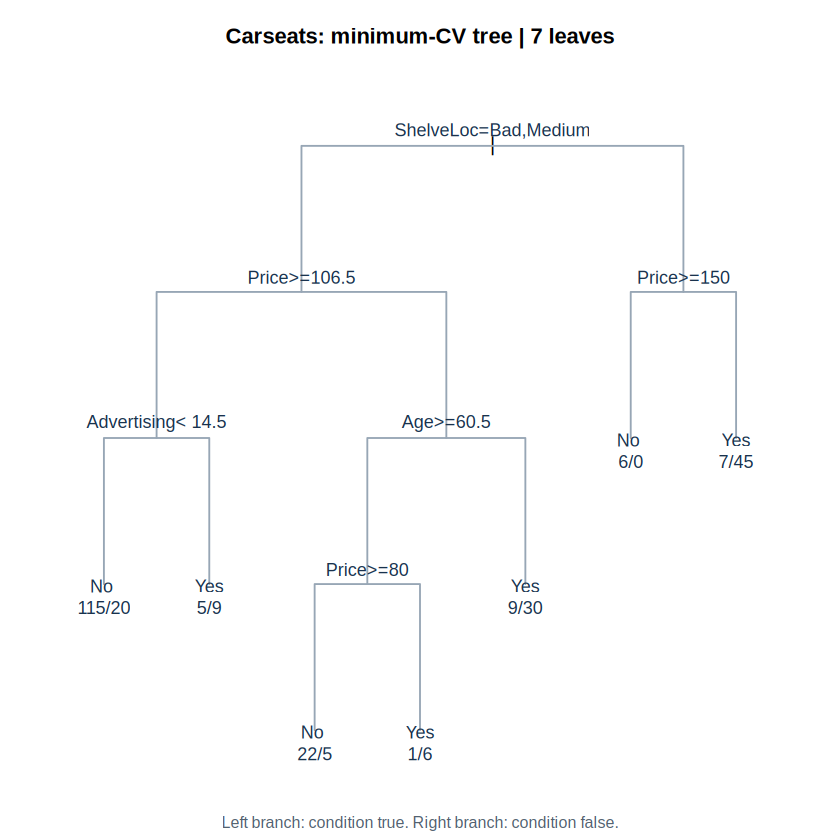

In [10]:
plot_lab_tree(car_min, "Carseats: minimum-CV tree", cex = .9)


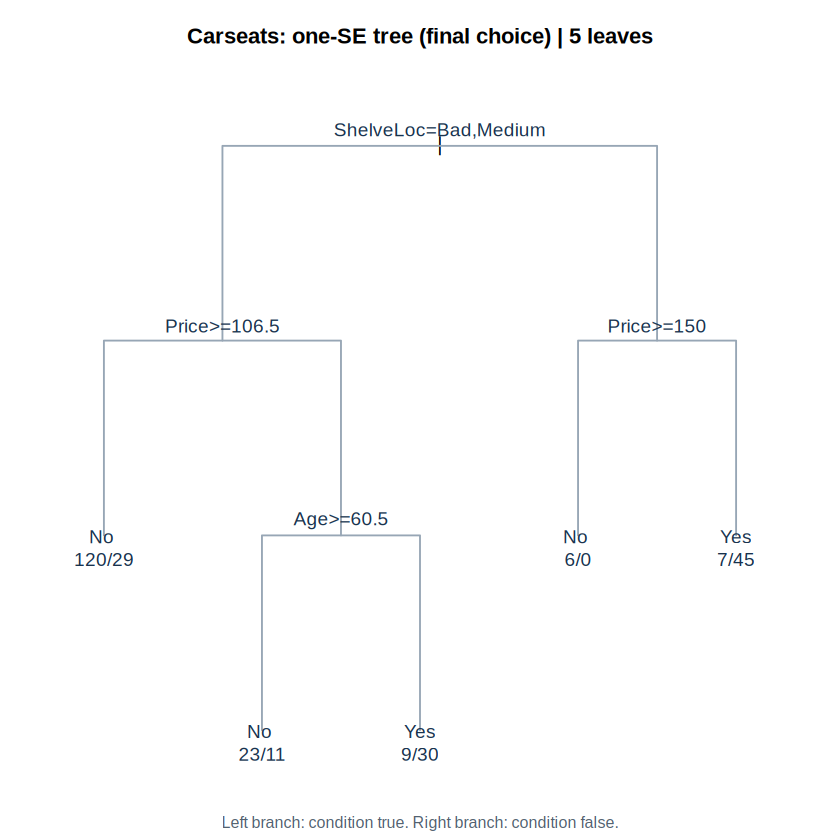

In [11]:
plot_lab_tree(car_1se, "Carseats: one-SE tree (final choice)", cex = .95)


In [12]:
print(car_1se, digits = 6)


n= 280 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 280 115 No (0.589286 0.410714)  
   2) ShelveLoc=Bad,Medium 222  70 No (0.684685 0.315315)  
     4) Price>=106.5 149  29 No (0.805369 0.194631) *
     5) Price< 106.5 73  32 Yes (0.438356 0.561644)  
      10) Age>=60.5 34  11 No (0.676471 0.323529) *
      11) Age< 60.5 39   9 Yes (0.230769 0.769231) *
   3) ShelveLoc=Good 58  13 Yes (0.224138 0.775862)  
     6) Price>=150 6   0 No (1.000000 0.000000) *
     7) Price< 150 52   7 Yes (0.134615 0.865385) *


In [13]:
car_cutoff
car_cutoff*car_root_error
car_cv[car_eligible, ]


[1] 0.5723832

[1] 0.2350859

,CP,leaves,training_error,CV_error,CV_SE
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4,0.043478261,5,0.2000000,0.2321429,0.02523126
5,0.034782609,6,0.1821429,0.2321429,0.02523126
6,0.026086957,7,0.1678571,0.2107143,0.02437166
7,0.021739130,8,0.1571429,0.2214286,0.02481344
8,0.017391304,10,0.1392857,0.2214286,0.02481344
9,0.008695652,13,0.1178571,0.2178571,0.02466891
10,0.002173913,15,0.1107143,0.2250000,0.02495532
11,0.000000000,19,0.1071429,0.2250000,0.02495532


3.1: The grown tree has 19 leaves and a CP of 0.000. The minimum CV tree has 7 leaves and a CP of 0.026. The one-SE tree has 5 leaves and a CP of 0.043. The one SE cutoff is 0.572 on the relative error scale and 0.235 on the error rate scale. The error rate cutoff is calculated using the minimum CV tree which has 7 leaves.
0.2107143+0.02437166=0.23508596=0.235
The relative error cutoff is then calculated by dividing by the root node error rate:
0.23508596/0.410714=0.572
The rows that qualify are rows 4-11 because their CV error rates are at or below the one-SE cutoff of 0.235. The rule selects the largest CP because it makes the simplest tree with the fewest amount of leaves and it also keeps the CV error within one SE of the minimum.

3.2: The training error decreases as the number of leaves increases. This is because the tree can fit the development data more closely. The CV error decreases initially but then fluctuates as the tree becomes more complex and begins overfitting. The smallest training error doesn't settle the choice because it uses the same data for measuring performance as  was used to build the tree. The one SE rule prefers a simpler tree whose CV error is close to the minimum because it helps to reduce overfitting. Pruning does not gurrantee lower error on every future sample.

3.3: For a store with ShelveLoc=Good and Price = 120 the tree follows the ShelveLoc=Good branch and Price < 150 branch reaching terminal node 7. The leaf probability of Yes is 0.865 and predicted class is Yes because 0.865 is greater than 0.50. This probability is not a guarantee because it is estimated from development stores in that leaf and an individual new store may have a different outcome.

Question 4.1:
Leaf prediction:
Left Child: (20+22+24)/3=22
Right Child: (30+32+34)/3=32
Total child RSS=
RSSleft=(20-22)^2+(22-22)^2+(24-22)^2=8
RSSright=(30-32)^2+(32-32)^2+(34-32)^2=8
=Total child rss=8+8=16
Root only prediction=(20+22+24+30+32+34)/6=27

Root RSS= (20-27)^2+(22-27)^2+(24-27)^2+(30-27)^2+(32-27)^2+(34-27)^2=166

The regression trees choose splits by minimizing rss while the classification tree uses Gini impurity to choose splits based on class proportions.

In [14]:
auto <- ISLR2::Auto[, c("mpg", "horsepower", "weight", "year", "origin")]
auto$origin <- factor(auto$origin, levels = 1:3,
                       labels = c("American", "European", "Japanese"))
set.seed(4632)
auto_dev_id <- sample(seq_len(nrow(auto)), round(.70 * nrow(auto)))
auto_dev <- auto[auto_dev_id, ]
auto_test <- auto[-auto_dev_id, ]
data.frame(set = c("Development", "Test"),
           n = c(nrow(auto_dev), nrow(auto_test)))
colSums(is.na(auto_dev))

set.seed(4633)
auto_full <- rpart(
  mpg ~ ., data = auto_dev, method = "anova",
  control = rpart.control(cp = 0, minsplit = 20, minbucket = 7,
                          maxdepth = 5, xval = 10))
auto_cp <- auto_full$cptable
printcp(auto_full)

set,n
<chr>,<int>
Development,274
Test,118


mpg horsepower     weight       year     origin 
         0          0          0          0          0


Regression tree:
rpart(formula = mpg ~ ., data = auto_dev, method = "anova", control = rpart.control(cp = 0, 
    minsplit = 20, minbucket = 7, maxdepth = 5, xval = 10))

Variables actually used in tree construction:
[1] horsepower weight     year      

Root node error: 15057/274 = 54.954

n= 274 

           CP nsplit rel error  xerror     xstd
1  0.58887652      0   1.00000 1.00896 0.070103
2  0.10055358      1   0.41112 0.46271 0.051541
3  0.04827294      2   0.31057 0.40389 0.048687
4  0.04755359      3   0.26230 0.36934 0.045162
5  0.04487694      4   0.21474 0.36865 0.045149
6  0.01575703      5   0.16987 0.27801 0.039489
7  0.01023285      6   0.15411 0.24091 0.034365
8  0.00759115      7   0.14388 0.21531 0.031664
9  0.00642872      8   0.13629 0.20160 0.028051
10 0.00557680      9   0.12986 0.20281 0.028935
11 0.00458082     10   0.12428 0.20104 0.028803
12 0.00294045     11   0.11970 0.19526 0.028277
13 0.00211014     12   0.11676 0.19113 0.028583
14 0.00166872     13   0.1

In [15]:
auto_min_row <- which.min(auto_cp[, "xerror"])
auto_cp_min <- auto_cp[auto_min_row, "CP"]
auto_cutoff <- auto_cp[auto_min_row, "xerror"] +
               auto_cp[auto_min_row, "xstd"]
auto_eligible <- which(auto_cp[, "xerror"] <= auto_cutoff)
auto_cp_1se <- max(auto_cp[auto_eligible, "CP"])
auto_min <- prune(auto_full, cp = auto_cp_min)
auto_1se <- prune(auto_full, cp = auto_cp_1se)
auto_models <- list(Grown = auto_full, Minimum_CV = auto_min, One_SE = auto_1se)
auto_root_mse <- auto_full$frame$dev[1] / nrow(auto_dev)
auto_cv <- data.frame(
  CP = auto_cp[, "CP"], leaves = auto_cp[, "nsplit"] + 1,
  training_MSE = auto_cp[, "rel error"] * auto_root_mse,
  CV_MSE = auto_cp[, "xerror"] * auto_root_mse,
  CV_SE_MSE = auto_cp[, "xstd"] * auto_root_mse)
knitr::kable(auto_cv, digits = 4)
data.frame(model = names(auto_models),
           CP = c(0, auto_cp_min, auto_cp_1se),
           leaves = vapply(auto_models, function(f) {
             sum(f$frame$var == "<leaf>")
           }, numeric(1)))



|     CP| leaves| training_MSE|  CV_MSE| CV_SE_MSE|
|------:|------:|------------:|-------:|---------:|
| 0.5889|      1|      54.9541| 55.4462|    3.8524|
| 0.1006|      2|      22.5929| 25.4280|    2.8324|
| 0.0483|      3|      17.0671| 22.1952|    2.6756|
| 0.0476|      4|      14.4143| 20.2966|    2.4818|
| 0.0449|      5|      11.8010| 20.2591|    2.4811|
| 0.0158|      6|       9.3349| 15.2775|    2.1701|
| 0.0102|      7|       8.4689| 13.2391|    1.8885|
| 0.0076|      8|       7.9066| 11.8321|    1.7400|
| 0.0064|      9|       7.4894| 11.0785|    1.5415|
| 0.0056|     10|       7.1362| 11.1450|    1.5901|
| 0.0046|     11|       6.8297| 11.0482|    1.5828|
| 0.0029|     12|       6.5780| 10.7305|    1.5539|
| 0.0021|     13|       6.4164| 10.5035|    1.5707|
| 0.0017|     14|       6.3004| 10.6968|    1.5744|
| 0.0008|     15|       6.2087| 10.5399|    1.5725|
| 0.0000|     16|       6.1674| 10.3963|    1.5722|

,model,CP,leaves
,<chr>,<dbl>,<dbl>
Grown,Grown,0.000000000,16
Minimum_CV,Minimum_CV,0.000000000,16
One_SE,One_SE,0.007591153,8


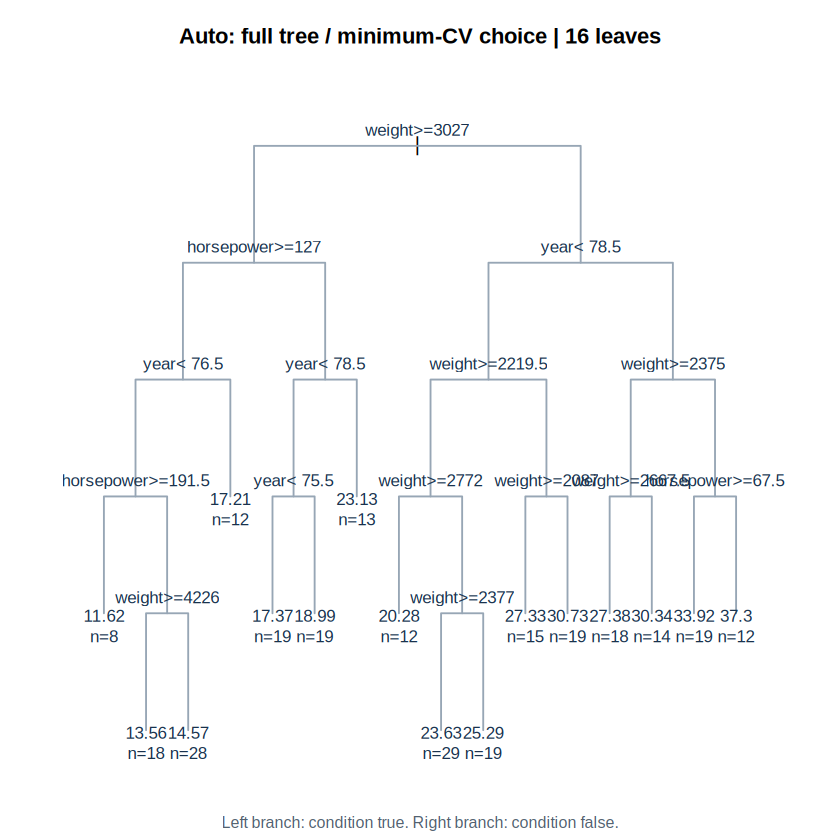

In [16]:
plot_lab_tree(auto_full, "Auto: full tree / minimum-CV choice", cex = .85)


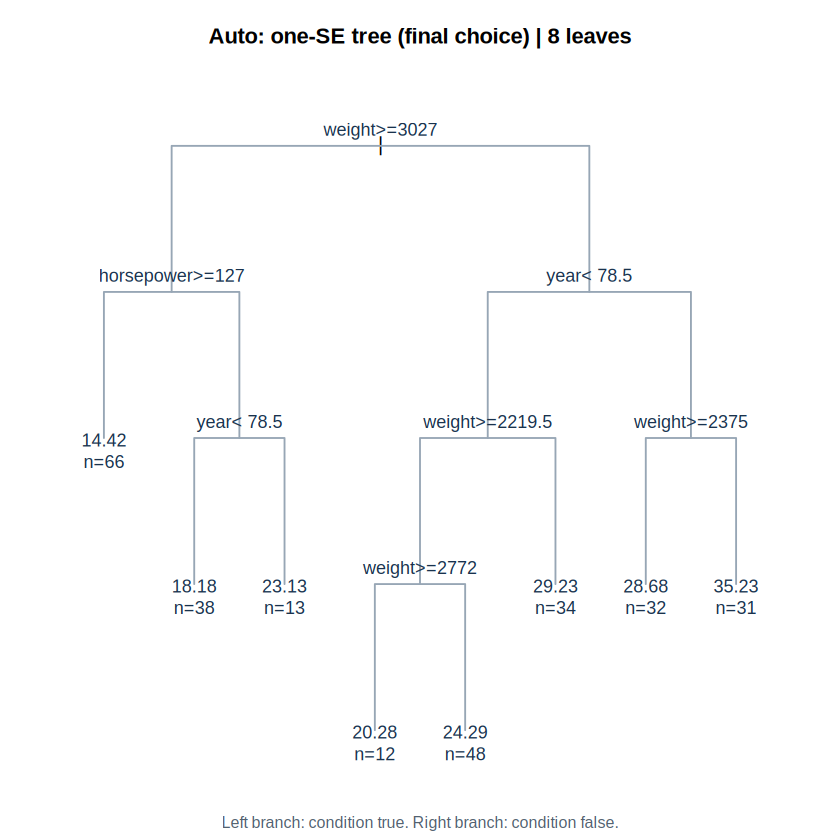

In [17]:
plot_lab_tree(auto_1se, "Auto: one-SE tree (final choice)", cex = .9)


In [18]:
print(auto_1se, digits = 6)


n= 274 

node), split, n, deviance, yval
      * denotes terminal node

 1) root 274 15057.4000 23.1974  
   2) weight>=3027 117  1634.4200 16.6077  
     4) horsepower>=127 66   303.4920 14.4167 *
     5) horsepower< 127 51   604.0650 19.4431  
      10) year< 78.5 38   131.4170 18.1816 *
      11) year>=78.5 13   235.3880 23.1308 *
   3) weight< 3027 157  4556.0400 28.1083  
     6) year< 78.5 94  1526.0100 25.5660  
      12) weight>=2219.5 60   459.9620 23.4883  
        24) weight>=2772 12    58.0367 20.2833 *
        25) weight< 2772 48   247.8450 24.2896 *
      13) weight< 2219.5 34   350.0140 29.2324 *
     7) year>=78.5 63  1515.9500 31.9016  
      14) weight>=2375 32   459.6750 28.6781 *
      15) weight< 2375 31   380.5440 35.2290 *


4.2: The Auto development size is 274 and the test size is 118. The minimum CV CP is 0.000. The one SE cutoff is (0.18918+0.028609)= 0.218 and the selected CP is 0.008. The leaf count before pruning is 16 while the count after is 8. One path is starting at the Root then weight>=3027 then horsepower>=127 then terminal node=4. The pruned trees training MSE is 7.91 mpg^2 while the training RMSE is 2.812 mpg. The RMSE is easier to interpret because it is measured in the same units as the response variable which is mpg. The MSE is measured in squared mpg units.

In [19]:
predict<-predict(auto_1se,newdata=auto_dev)
mse<-mean((auto_dev$mpg-predict)^2)
rmse<-sqrt(mse)
mse
rmse

[1] 7.906609

[1] 2.811869

####Group Checkpoint: Spot the Problems


Case A: An Excellent Sales Classifier

What is wrong: "Sales" appears to remain in the predictor set; essentially, the code appears to evaluate the model based on its training data.

Why it matters: This is an issue because it may yield an overly optimistic response - the model is unable to learn about other underlying predictors.

How to fix it: In order to fix this, "Sales" can be removed from the dataset prior to fitting the tree. Then, the model's ability to generalize can be tested using cross-validation.

Case B: The Best-Looking Training Fit

What is wrong: This assumption that minimizing the training error yields the best model is inaccurate. An unpruned tree may overfit the training data and capture noise, rather than true trends.

Why it matters: Though an unpruned tree is able to attain the lowest training error, its drawback is that it's unable to generalize as well. Thus, its performance may be worse, as its unable to perform on unseen data.

How to fix it: In this case, cost-complexity pruning may be used to trim splits that may not be necessary. This may help find a tree size that minimizes complexity and maintains simplicity, without hindering predictive performance.

Case C: One SE from the Wrong Column

What is wrong: In this case, the one-SE rule was applied incorrectly - the rather than picking the simplest tree whose CV error is within 1 SE of the minimum, Ana picked the most complex tree. Additionally, the code appears to incorrectly compare "rel error" to "xerror".

Why it matters: With the one-SE rule, the ultimate intention is to select the simplest model (whose error is relatively close to the minimum) in an attempt to prevent overfitting. Picking the "most detailed tree" yields a model that may have an increased tendency to overfit.

How to fix it: This can be fixed by pinpointing the simplest tree, rather than the most detailed one (this would correspond to the max CP value, rather than the min CP value).

Case D: A Last Adjustment

What is wrong: This is an instance of data leakage - Ben is using the test set to pick the best CP value, and then proceeds to use that performance on the very same same test set as the basis for the final model evaluation score.

Why it matters: Since the hyper-parameter (the CP value) was picked to minimize error, this may have introduced bias into the system, making the model overly optimistic.

How to fix it: This can be corrected by choosing the optimal CP hyper-parameter solely on the training data using cross-validation. Then, once the final model is chosen, the model's test error score can be computed using an data from an unseen test set.

####Final Test Evaluation

In [20]:
car_test_prob <- predict(car_1se, newdata = car_test,
                         type = "prob")[, "Yes"]
car_test_class <- factor(ifelse(car_test_prob >= .50, "Yes", "No"),
                          levels = c("No", "Yes"))
car_cm <- table(Actual = car_test$High, Predicted = car_test_class)
car_cm
car_majority <- names(which.max(table(car_dev$High)))
car_test_results <- data.frame(
  model = c("One-SE tree", "Development majority baseline"),
  error = c(mean(car_test_class != car_test$High),
            mean(car_test$High != car_majority)))
knitr::kable(car_test_results, digits = 3)
c(recall_Yes = car_cm["Yes", "Yes"] / sum(car_cm["Yes", ]),
  specificity_No = car_cm["No", "No"] / sum(car_cm["No", ]))

      Predicted
Actual No Yes
   No  55  16
   Yes 19  30



|model                         | error|
|:-----------------------------|-----:|
|One-SE tree                   | 0.292|
|Development majority baseline | 0.408|

recall_Yes specificity_No 
     0.6122449      0.7746479

In [21]:
auto_test_pred <- predict(auto_1se, newdata = auto_test)
auto_test_mse <- mean((auto_test$mpg - auto_test_pred)^2)
auto_baseline_mse <- mean((auto_test$mpg - mean(auto_dev$mpg))^2)
auto_test_results <- data.frame(
  model = c("One-SE tree", "Development mean baseline"),
  MSE = c(auto_test_mse, auto_baseline_mse),
  RMSE = sqrt(c(auto_test_mse, auto_baseline_mse)))
knitr::kable(auto_test_results, digits = 3)



|model                     |    MSE|  RMSE|
|:-------------------------|------:|-----:|
|One-SE tree               | 13.593| 3.687|
|Development mean baseline | 74.456| 8.629|

**Q5.1**

The test error for the classification tree is 0.292, and its baseline is 0.408. Using the confusion matrix, the number of high-sales stores the tree misses is 19, and the number of low-sales stores it incorrectly labels is 16. In regards to recall, the model correctly identifies 61.2% of true high-sales stores (the tree is able to pinpoint most high-sales locations accurately). In regards to specificity, the model correctly labels 77.5% of low-sales stores as "No" (which means the tree is relatively successful at avoiding false alarms).

**Q5.2**

The MSE and the RMSE for the regression tree is 13.593 and 3.687 respectively. The MSE and the RMSE for the baseline is 74.456 and 8.629 respectively. Taking a looking at the error, the results show that the pruned regression tree performs better than the baseline. One potential limitation of the data/split is sampling bias, as how the data was split could affect the values of the resulting metrics. The CP should not be adjusted using the test results because this may result in data leakage, therefore causing the model to potentially perform in a manner that's overly optimistic.

AI Statement: I used AI for assistance for working through code and explanations in the assignment. I also used it to checking if I was understanding the content correctly. I verified its contribution by making sure I understood everything and making sure to verify with the course notes.



